<a href="https://colab.research.google.com/github/Swarajkarle/Development-of-AI-Based-Knowledge-Retrieval-Platform-with-Query-Resolution-System/blob/main/SQL_Interview__Questions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

data = pd.DataFrame({
    'x': [0,0,1,1],
    'y': [0,1,0,1],
    'z': [10,12,14,16]
})

data.to_csv("data.csv", index=False)

print(data)

   x  y   z
0  0  0  10
1  0  1  12
2  1  0  14
3  1  1  16


Saving sample_data.csv to sample_data.csv


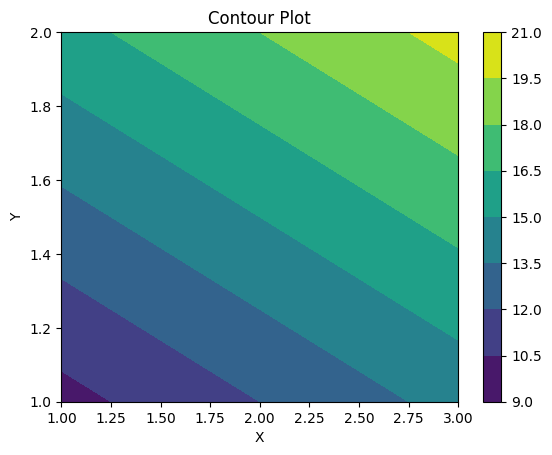

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Upload CSV file
from google.colab import files
uploaded = files.upload()

# Read file
filename = list(uploaded.keys())[0]
data = pd.read_csv(filename)

# Extract values
x = data['x']
y = data['y']
z = data['z']

# Create grid
xi = np.linspace(min(x), max(x), 50)
yi = np.linspace(min(y), max(y), 50)
xi, yi = np.meshgrid(xi, yi)

# Interpolation
from scipy.interpolate import griddata
zi = griddata((x, y), z, (xi, yi), method='cubic')

# Plot contour
plt.figure()
cp = plt.contourf(xi, yi, zi)
plt.colorbar(cp)
plt.title("Contour Plot")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()


In [ ]:
import pandas as pd

# Example data
data = {
    "Line": ["AB", "BC", "CD", "DA"],
    "Length": [100, 120, 90, 110],
    "Bearing": [30, 120, 210, 300]  # in degrees
}

df = pd.DataFrame(data)

# Convert to radians
import numpy as np
df["Bearing_rad"] = np.radians(df["Bearing"])

# Calculate latitude & departure
df["Latitude"] = df["Length"] * np.cos(df["Bearing_rad"])
df["Departure"] = df["Length"] * np.sin(df["Bearing_rad"])

# Corrections (Bowditch approx)
lat_error = df["Latitude"].sum()
dep_error = df["Departure"].sum()
total_length = df["Length"].sum()

df["Corr_Lat"] = -lat_error * (df["Length"] / total_length)
df["Corr_Dep"] = -dep_error * (df["Length"] / total_length)

df["Adj_Lat"] = df["Latitude"] + df["Corr_Lat"]
df["Adj_Dep"] = df["Departure"] + df["Corr_Dep"]

print(df)

  Line  Length  Bearing  Bearing_rad   Latitude   Departure  Corr_Lat  \
0   AB     100       30     0.523599  86.602540   50.000000 -0.871489   
1   BC     120      120     2.094395 -60.000000  103.923048 -1.045787   
2   CD      90      210     3.665191 -77.942286  -45.000000 -0.784340   
3   DA     110      300     5.235988  55.000000  -95.262794 -0.958638   

   Corr_Dep    Adj_Lat     Adj_Dep  
0 -3.252441  85.731051   46.747559  
1 -3.902930 -61.045787  100.020119  
2 -2.927197 -78.726626  -47.927197  
3 -3.577686  54.041362  -98.840480  


In [ ]:
import pandas as pd
import numpy as np

# Input
lengths = [100, 120, 90, 110]
bearings = [30, 120, 210, 300]

lat = []
dep = []

for l, b in zip(lengths, bearings):
    rad = np.radians(b)
    lat.append(l * np.cos(rad))
    dep.append(l * np.sin(rad))

lat_error = sum(lat)
dep_error = sum(dep)
total_length = sum(lengths)

adj_lat = []
adj_dep = []

for i in range(len(lengths)):
    corr_lat = -lat_error * (lengths[i] / total_length)
    corr_dep = -dep_error * (lengths[i] / total_length)

    adj_lat.append(lat[i] + corr_lat)
    adj_dep.append(dep[i] + corr_dep)

print("Adjusted Latitudes:", adj_lat)
print("Adjusted Departures:", adj_dep)

Adjusted Latitudes: [np.float64(85.73105132181425), np.float64(-61.04578686795553), np.float64(-78.72662649156615), np.float64(54.04136203770742)]
Adjusted Departures: [np.float64(46.74755856241799), np.float64(100.02011872903424), np.float64(-47.92719729382381), np.float64(-98.84047999762845)]


In [ ]:

import math

k = 100
c = 0

s = float(input("Enter staff intercept (m): "))
theta = float(input("Enter angle (degrees): "))

theta_rad = math.radians(theta)

distance = k * s + c
elevation = distance * math.tan(theta_rad)

print("Horizontal Distance =", distance)
print("Elevation =", elevation)

Enter staff intercept (m): 0.5
Enter angle (degrees): 30
Horizontal Distance = 50.0
Elevation = 28.867513459481287


In [ ]:
import math

R = float(input("Enter radius (m): "))
delta = float(input("Enter deflection angle (degrees): "))
chain = float(input("Enter chain length (m): "))


n = int((delta * math.pi/180 * R) / chain)

deflections = []

for i in range(1, n+1):
    angle = (chain / (2 * R)) * (180 / math.pi) * i
    deflections.append(angle)

print("Deflection angles:")
for i, d in enumerate(deflections):
    print(f"Point {i+1}: {d:.2f} degrees")

Enter radius (m): 5
Enter deflection angle (degrees): 45
Enter chain length (m): 6
Deflection angles:


Predicted Strength = 36.99999999999999
Model Accuracy = 1.0


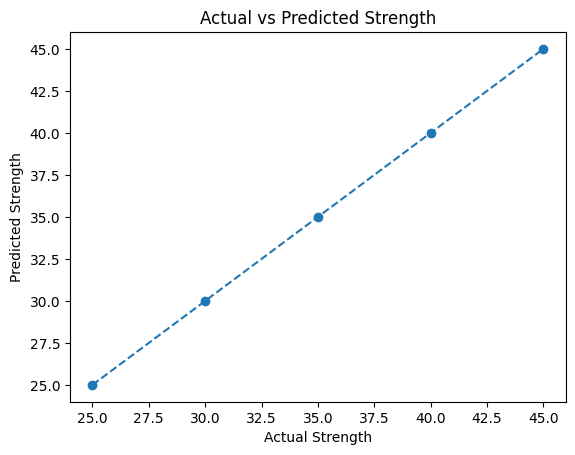

In [ ]:

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt


data = {
    "cement": [300, 350, 400, 450, 500],
    "water": [180, 175, 170, 165, 160],
    "aggregate": [1200, 1150, 1100, 1050, 1000],
    "strength": [25, 30, 35, 40, 45]
}

df = pd.DataFrame(data)

# -------------------------------

X = df[["cement", "water", "aggregate"]]
y = df["strength"]


# -------------------------------
model = LinearRegression()
model.fit(X, y)


# -------------------------------
new_data = pd.DataFrame({
    "cement": [420],
    "water": [168],
    "aggregate": [1080]
})

pred = model.predict(new_data)

print("Predicted Strength =", pred[0])


# -------------------------------
accuracy = model.score(X, y)
print("Model Accuracy =", accuracy)


# -------------------------------
y_pred = model.predict(X)

plt.figure()
plt.scatter(y, y_pred)
plt.xlabel("Actual Strength")
plt.ylabel("Predicted Strength")
plt.title("Actual vs Predicted Strength")


plt.plot(y, y, linestyle='--')

plt.show()

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression

# Data
data = {
    "velocity": [1, 2, 3, 4, 5],
    "diameter": [0.1]*5,
    "viscosity": [0.001]*5,
    "length": [10]*5,
    "pressure_drop": [100, 200, 300, 420, 550]
}

df = pd.DataFrame(data)

X = df[["velocity", "diameter", "viscosity", "length"]]
y = df["pressure_drop"]

model = LinearRegression()
model.fit(X, y)

# Prediction
new_data = pd.DataFrame({
    "velocity": [3.5],
    "diameter": [0.1],
    "viscosity": [0.001],
    "length": [10]
})

pred = model.predict(new_data)

print("Predicted Pressure Drop =", pred[0])
print("Accuracy =", model.score(X, y))

Predicted Pressure Drop = 370.0
Accuracy = 0.9961880559085133


In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression

# Data
data = {
    "load": [10, 20, 30, 40, 50],
    "span": [2]*5,
    "E": [200]*5,
    "I": [5000]*5,
    "deflection": [2, 4, 6, 8, 10]
}

df = pd.DataFrame(data)

X = df[["load", "span", "E", "I"]]
y = df["deflection"]

model = LinearRegression()
model.fit(X, y)

# Prediction
new_data = pd.DataFrame({
    "load": [35],
    "span": [2],
    "E": [200],
    "I": [5000]
})

pred = model.predict(new_data)

print("Predicted Deflection =", pred[0])
print("Accuracy =", model.score(X, y))

Predicted Deflection = 7.000000000000001
Accuracy = 1.0
